# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 19: Análise de Ortogonalidade, Efeito Oráculo e Grau de Consenso no Random Forest — Classe LARGE

**Autor:** Evandro Rocha (UFRJ / COPPE / PEE)
**Data:** Outubro de 2026

---

## Resumo Executivo da Investigação com Random Forest (RF)

A classe **`LARGE`** (embarcações com comprimento ≥ 100 m, conforme `src/iara/default.py`) foi avaliada em **2.140 instâncias de teste** (arquivo × fold; **572 gravações distintas** de **417 navios**) nos 10 folds do protocolo 5×2cv, com **Random Forest (100 árvores, `class_weight='balanced'`)** nas 4 representações (**MEL, LOFAR, HHT e DEMON**).

O objetivo é confrontar os resultados do SVM (Notebook 15) e do MLP (Notebook 18) com os do Random Forest na classe `LARGE`.

> **Atenção — estes não são os RF do artigo.** Os quatro modelos foram treinados por `scratch/generate_rf_predictions_and_analysis.py` (100 árvores, sem `max_depth`, `class_weight='balanced'`). Para MEL e LOFAR, o script usa caches com **média em 5,12 s** (`mel5s`/`lofar5s`: o arquivo 1 tem 55 frames, contra 551 nas features oficiais de 0,512 s). Por isso, "RF MEL" e "RF LOFAR" aqui (SP 61,50 ± 1,89 e 63,07 ± 1,81) **não são o mesmo modelo** do RF da Tabela 7 do artigo (MEL 62,22 ± 1,86; LOFAR 56,92 ± 1,69). Não compare esses valores como se fossem o mesmo experimento.
>
> O split do 5×2cv é **por gravação** (`exclusive_header='ID'`), como no artigo: o mesmo navio (`Ship ID`) pode aparecer no treino e no teste.
>
> RF DEMON é fraco no problema de 4 classes (SP 44,44 ± 2,24); seus resgates e acertos nesta classe devem ser lidos com isso em mente.

### Principais Descobertas no Random Forest:
1. **Oráculo RF de 90,98% (1.947 / 2.140 instâncias), não realizável; sob erros independentes o esperado seria 99,34%:**
   - Oráculos das três famílias: SVM 90,84%, MLP 89,25%, RF 90,98%.
   - Erro comum (as 4 erram): **193 instâncias (9,02%)**.
2. **Unanimidade 4/4 de 46,31%:** 991 instâncias arquivo × fold, que correspondem a **314 gravações distintas** (não "navios"). SVM: 40,14%; MLP: 44,44%. Com o alto consenso, **68,04% (1.456 instâncias)** são acertadas por pelo menos 3 entradas.
3. **Maior número de resgates exclusivos: DEMON** (112 instâncias = 64 gravações de 57 navios; 10 dessas gravações são exclusivas do DEMON em todas as aparições).
4. **Votação:** "≥2/4" dá 80,42%, mas conta 158 empates 2×2 como acerto e não é realizável. O **voto real** tem recall em `LARGE` de **77,10% ± 2,59** e não difere significativamente do melhor isolado (LOFAR, 75,79% ± 2,00; F-test 5×2cv, p = 0,553).

In [1]:
# 1. Configuração do Ambiente e Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 13,
                     'xtick.labelsize': 10, 'ytick.labelsize': 10, 'figure.titlesize': 15, 'figure.dpi': 150})
pd.set_option('display.precision', 2)
print("Ambiente configurado com sucesso! Bibliotecas prontas.")

Ambiente configurado com sucesso! Bibliotecas prontas.


In [2]:
# Funções de análise de complementaridade (o gerador usa este mesmo código para os números do texto)
import os
import sys
import numpy as np
import pandas as pd

for _p in (os.getcwd(), os.path.join(os.getcwd(), 'src'), os.path.join(os.getcwd(), 'notebooks'), os.path.join(os.getcwd(), 'notebooks', 'src')):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and _p not in sys.path:
        sys.path.insert(0, _p)
import iara_results as R

REPS = ['MEL', 'LOFAR', 'HHT', 'DEMON']
FAMILIAS = {
    # Random Forest (scratch/generate_rf_predictions_and_analysis.py): 100 árvores, sem max_depth,
    # class_weight='balanced'. MEL e LOFAR usam caches com média em 5,12 s (mel5s/lofar5s).
    'RF': {'MEL': 'rf_mel5s_n100_balanced_4c', 'LOFAR': 'rf_lofar5s_n100_balanced_4c',
           'HHT': 'rf_hht_n100_balanced_4c', 'DEMON': 'rf_demon_n100_balanced_4c'},
    # SVM Nyström (Notebooks 13/12/13; scratch/save_svm_all_representations.py)
    'SVM': {'MEL': 'svm_nystroem_4000_log_melgram_elasticnet_l1r0.15_C2.0',
            'LOFAR': 'svm_nystroem_6000_lofar_elasticnet_l1r0.15',
            'HHT': 'svm_nystroem_4000_hht_C2.0_elasticnet_l1r0.15_4c',
            'DEMON': 'svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.15_4c'},
    # MLP (Notebooks 16/15/16; scratch/generate_mlp_predictions_and_analysis.py)
    'MLP': {'MEL': 'mlp', 'LOFAR': 'mlp_lofar',
            'HHT': 'mlp_hht_h32-16_e30_4c', 'DEMON': 'mlp_demon_h32-16_e30_4c'},
}
CLS = {nome: i for i, nome in enumerate(R.CLASSES)}


def nomes(familia):
    return [FAMILIAS[familia][r] for r in REPS]


def ship_ids():
    meta = pd.read_csv(os.path.join(R.ROOT, 'src', 'iara', 'dataset_info', 'iara.csv'),
                       dtype={'ID': str, 'Ship ID': str})
    return dict(zip(meta['ID'].astype(int), meta['Ship ID']))


def instancias(familia, classe):
    """Uma linha por instância (arquivo x fold de teste) da classe, com a predição de cada representação."""
    exps = FAMILIAS[familia]
    al = R.aligned(nomes(familia))
    df = pd.concat([d.assign(fold=k) for k, d in al.items()], ignore_index=True)
    df = df.rename(columns={exps[r]: r for r in REPS})
    df = df[df.Target == CLS[classe]].copy()
    df['Ship ID'] = df.File.map(ship_ids())
    return df


def analise_classe(familia, classe):
    c = CLS[classe]
    d = instancias(familia, classe)
    H = np.column_stack([d[r].values == c for r in REPS])   # acerto de cada representação
    k = H.sum(axis=1)                                         # nº de representações que acertam
    n = len(d)
    out = {'familia': familia, 'classe': classe, 'n_inst': n, 'n_grav': int(d.File.nunique()),
           'n_navios': int(d['Ship ID'].nunique()), 'n_sem_ship': int(d['Ship ID'].isna().sum())}

    rows = []
    for i, r in enumerate(REPS):
        s = R.summary(FAMILIAS[familia][r])
        rows.append({'Representação': r, 'Acertos (instâncias)': int(H[:, i].sum()),
                     'Recall agregado (%)': 100 * H[:, i].mean(),
                     'Recall médio nos folds (%)': s['R_' + classe][0], 'Desvio nos folds': s['R_' + classe][1],
                     'SP global 4c (%)': s['SP'][0], 'Desvio SP': s['SP'][1],
                     'Experimento': FAMILIAS[familia][r]})
    iso = pd.DataFrame(rows).set_index('Representação')
    out['isolado'] = iso
    best = iso['Recall médio nos folds (%)'].idxmax()
    out['melhor'] = best

    orc = R.oracle_recall(nomes(familia)).loc[classe]
    out['oraculo'] = {'acertos': int((k >= 1).sum()), 'agregado': 100 * (k >= 1).mean(),
                      'obs_folds': float(orc.iloc[0]), 'esp_indep': float(orc.iloc[1])}

    niveis = (4, 3, 2, 1, 0)
    cons = pd.DataFrame({'Nível': [f'{j} de 4 acertam' for j in niveis],
                         'Instâncias': [int((k == j).sum()) for j in niveis],
                         'Gravações distintas': [int(d.File[k == j].nunique()) for j in niveis]})
    cons['% da classe'] = 100 * cons['Instâncias'] / n
    out['consenso'] = cons.set_index('Nível')[['Instâncias', '% da classe', 'Gravações distintas']]

    rows = []
    for i, r in enumerate(REPS):
        m = (k == 1) & H[:, i]
        todas = d.assign(excl=m).groupby('File').excl.all()
        rows.append({'Representação': r, 'Instâncias': int(m.sum()), '% da classe': 100 * m.mean(),
                     'Gravações distintas': int(d.File[m].nunique()),
                     'Navios distintos': int(d['Ship ID'][m].nunique()),
                     'Gravações exclusivas em todas as aparições': int(todas.sum())})
    out['exclusivos'] = pd.DataFrame(rows).set_index('Representação')
    m1 = k == 1
    out['excl_total'] = {'inst': int(m1.sum()), 'grav': int(d.File[m1].nunique()),
                         'navios': int(d['Ship ID'][m1].nunique())}

    b = H[:, REPS.index(best)]
    rows = []
    for i, r in enumerate(REPS):
        if r == best:
            continue
        rows.append({'Troca': f'{best} → {r}', 'Mantém acertos': int((b & H[:, i]).sum()),
                     'Perde acertos': int((b & ~H[:, i]).sum()), 'Resgata erros': int((~b & H[:, i]).sum())})
    rev = pd.DataFrame(rows).set_index('Troca')
    rev['% dos acertos perdidos'] = 100 * rev['Perde acertos'] / b.sum()
    rev['% dos erros resgatados'] = 100 * rev['Resgata erros'] / (~b).sum()
    rev['Saldo (instâncias)'] = rev['Resgata erros'] - rev['Perde acertos']
    out['reverso'] = rev

    rows = []
    for i, r in enumerate(REPS):
        e = d.loc[~H[:, i], r]
        row = {'Representação': r, 'Erros (instâncias)': int(len(e))}
        for cc in range(4):
            if cc != c:
                row[f'→ {R.CLASSES[cc]} (%)'] = 100 * (e == cc).mean() if len(e) else np.nan
        rows.append(row)
    out['erros'] = pd.DataFrame(rows).set_index('Representação')

    # "≥2/4" conta como acerto os empates 2x2 (as duas erradas concordam numa mesma classe): não é um voto real
    P = d[REPS].values
    empate = 0
    for row, h in zip(P[k == 2], H[k == 2]):
        errados = row[~h]
        empate += int(errados[0] == errados[1])
    mv = R.majority_vote(nomes(familia))   # voto real: pluralidade, empate sorteado (seed fixa)
    rb = R.fold_metrics(FAMILIAS[familia][best])['R_' + classe]
    F, p = R.f_test_5x2(mv['R_' + classe].values, rb.values)
    best_sp = iso['SP global 4c (%)'].idxmax()
    sb = R.fold_metrics(FAMILIAS[familia][best_sp])['SP']
    Fs, ps = R.f_test_5x2(mv['SP'].values, sb.values)
    out['voto'] = {'ge2_n': int((k >= 2).sum()), 'ge2': 100 * (k >= 2).mean(),
                   'ge3_n': int((k >= 3).sum()), 'ge3': 100 * (k >= 3).mean(), 'empates_2x2': empate,
                   'recall': (mv['R_' + classe].mean(), mv['R_' + classe].std(ddof=0)),
                   'melhor': (rb.mean(), rb.std(ddof=0)), 'F': F, 'p': p,
                   'sp': (mv['SP'].mean(), mv['SP'].std(ddof=0)), 'melhor_sp_rep': best_sp,
                   'melhor_sp': (sb.mean(), sb.std(ddof=0)), 'F_sp': Fs, 'p_sp': ps}
    return out


def tabela_voto(a):
    v = a['voto']
    return pd.DataFrame([
        {'Critério': 'Unanimidade (4/4)', f'Recall {a["classe"]} (%)': a['consenso']['% da classe'].iloc[0],
         'Observação': 'contagem agregada'},
        {'Critério': 'Maioria estrita (≥3/4)', f'Recall {a["classe"]} (%)': v['ge3'],
         'Observação': 'contagem agregada'},
        {'Critério': '≥2/4 (empate 2×2 contado como acerto)', f'Recall {a["classe"]} (%)': v['ge2'],
         'Observação': f'NÃO realizável: inclui {v["empates_2x2"]} empates 2×2'},
        {'Critério': 'Voto real (pluralidade, empate sorteado)', f'Recall {a["classe"]} (%)': v['recall'][0],
         'Observação': f'média ± {v["recall"][1]:.2f} nos folds; F-test vs {a["melhor"]}: p = {v["p"]:.3f}'},
        {'Critério': f'Melhor isolado ({a["melhor"]})', f'Recall {a["classe"]} (%)': v['melhor'][0],
         'Observação': f'média ± {v["melhor"][1]:.2f} nos folds'},
        {'Critério': 'Oráculo (≥1/4)', f'Recall {a["classe"]} (%)': a['oraculo']['agregado'],
         'Observação': f'NÃO realizável; esperado c/ erros independentes: {a["oraculo"]["esp_indep"]:.2f}'},
    ]).set_index('Critério')


def resumo_familias(classe, familias=('SVM', 'MLP', 'RF')):
    A = {f: analise_classe(f, classe) for f in familias}
    rows = {}
    for f, a in A.items():
        iso, ex, v = a['isolado'], a['exclusivos'], a['voto']
        b = a['melhor']
        champ = ex['Instâncias'].idxmax()
        rows[f] = {
            'Melhor isolado: recall médio ± desvio (%)': f"{b}: {iso.loc[b, 'Recall médio nos folds (%)']:.2f} ± {iso.loc[b, 'Desvio nos folds']:.2f}",
            'Oráculo observado (agregado, %)': f"{a['oraculo']['agregado']:.2f}",
            'Oráculo esperado c/ erros independentes (%)': f"{a['oraculo']['esp_indep']:.2f}",
            'Unanimidade 4/4 (%)': f"{a['consenso']['% da classe'].iloc[0]:.2f}",
            'Erro comum 0/4 (%)': f"{a['consenso']['% da classe'].iloc[-1]:.2f}",
            'Maior resgate exclusivo': f"{champ}: {ex.loc[champ, 'Instâncias']} inst. / {ex.loc[champ, 'Gravações distintas']} grav.",
            '≥2/4 com empates (não realizável, %)': f"{v['ge2']:.2f}",
            'Voto real: recall (%) [p vs melhor isolado]': f"{v['recall'][0]:.2f} ± {v['recall'][1]:.2f} [p = {v['p']:.3f}]",
        }
    return pd.DataFrame(rows), A


def f_test_melhores(A, classe, ref='RF'):
    """F-test 5x2cv entre o recall da classe do melhor isolado de `ref` e o das outras famílias."""
    out = {}
    ra = R.fold_metrics(FAMILIAS[ref][A[ref]['melhor']])['R_' + classe].values
    for f, a in A.items():
        if f == ref:
            continue
        rb = R.fold_metrics(FAMILIAS[f][a['melhor']])['R_' + classe].values
        out[f] = R.f_test_5x2(ra, rb)
    return out

## 2. Metodologia Experimental e Base de Dados de Teste

Avaliação sobre a classe real **`LARGE` (Classe 2)** nos conjuntos de teste dos 10 folds do 5×2cv, com as 4 representações (**MEL, LOFAR, HHT e DEMON**) no Random Forest.

**Como contar.** Cada linha das tabelas abaixo é uma **instância arquivo × fold de teste** (predição por arquivo = voto majoritário das janelas, como no pipeline `iara`):
- **2.140 instâncias** de teste de `LARGE`;
- **572 gravações distintas** (cada gravação aparece, em média, **3,74 vezes** como teste nos 10 folds — e não 5 vezes: parte dos arquivos de cada fold vai para validação);
- **417 navios distintos** (`Ship ID` em `src/iara/dataset_info/iara.csv`).

Percentuais "agregados" usam as 2.140 instâncias; "recall médio nos folds" é a média ± desvio (ddof=0) sobre os 10 folds, como no artigo.

> **Nota de reprodutibilidade.** O script de origem desempatava o voto das janelas pela menor classe; aqui usamos `Counter.most_common` (empate → classe da primeira janela), igual a `src/iara/ml/models/trainer.py`. Por isso as contagens diferem da versão anterior deste notebook em poucas instâncias (até ~1 p.p.).

In [3]:
# 2. Desempenho global dos 4 RF e dados da classe LARGE
CLASSE = 'LARGE'
display(R.table([(f'RF {r}', FAMILIAS['RF'][r]) for r in REPS], metrics=('SP', 'ACC', 'F1')))
print('Referência — RF da Tabela 7 do artigo (outro modelo: features de 0,512 s, outra configuração):')
display(pd.DataFrame({f'RF {rep} (artigo)': {m: R.fmt(v) for m, v in R.ARTICLE_TABLE7[('RF', rep)].items()}
                      for rep in ('MEL', 'LOFAR')}).T)

A = analise_classe('RF', CLASSE)
print(f"Instâncias arquivo×fold: {A['n_inst']} | gravações distintas: {A['n_grav']} | "
      f"navios distintos: {A['n_navios']} | aparições médias por gravação: {A['n_inst']/A['n_grav']:.2f}")

,SP,ACC,F1,SMALL,MEDIUM,LARGE,BACKGROUND,Experimento
Modelo,,,,,,,,
RF MEL,61.50 ± 1.89,61.61 ± 1.88,63.27 ± 1.68,57.87,58.72,67.10,62.76,rf_mel5s_n100_balanced_4c
RF LOFAR,63.07 ± 1.81,63.79 ± 1.70,64.92 ± 1.54,47.81,55.64,75.79,75.92,rf_lofar5s_n100_balanced_4c
RF HHT,57.64 ± 2.14,58.11 ± 2.03,60.21 ± 2.04,53.43,46.58,74.07,58.37,rf_hht_n100_balanced_4c
RF DEMON,44.44 ± 2.24,46.08 ± 1.79,47.16 ± 1.94,52.47,35.10,68.79,27.96,rf_demon_n100_balanced_4c


Referência — RF da Tabela 7 do artigo (outro modelo: features de 0,512 s, outra configuração):


,SP,ACC,F1
RF MEL (artigo),62.22 ± 1.86,62.64 ± 1.84,63.79 ± 1.73
RF LOFAR (artigo),56.92 ± 1.69,58.87 ± 1.68,58.00 ± 1.41


Instâncias arquivo×fold: 2140 | gravações distintas: 572 | navios distintos: 417 | aparições médias por gravação: 3.74


## 3. O Efeito Oráculo no Random Forest: Recall Individual vs. Oráculo

O melhor RF isolado em `LARGE` é o **LOFAR**, com recall médio de **75,79% ± 2,00** nos folds (1.622 de 2.140 instâncias).

O **oráculo** (acerta se ALGUMA das 4 entradas acerta) chega a **90,98% (1.947 instâncias)**. Dois cuidados:
- o oráculo **não é um sistema realizável**: ele usa o rótulo verdadeiro para escolher a entrada;
- se os erros das 4 entradas fossem **independentes**, o esperado seria **99,34%** (1 − ∏(1 − rᵢ), média nos folds), contra **90,98%** observados na mesma média por fold. O oráculo fica **8,36 p.p. abaixo** do esperado sob independência: os erros das representações são **correlacionados** (tendem a cair nos mesmos áudios).

O erro comum (as 4 florestas erram) atinge **193 instâncias (9,02%)**.

,Acertos (instâncias),Recall agregado (%),Recall médio nos folds (%),Desvio nos folds,SP global 4c (%),Desvio SP,Experimento
Representação,,,,,,,
MEL,1436,67.10,67.10,3.68,61.50,1.89,rf_mel5s_n100_balanced_4c
LOFAR,1622,75.79,75.79,2.00,63.07,1.81,rf_lofar5s_n100_balanced_4c
HHT,1585,74.07,74.07,1.88,57.64,2.14,rf_hht_n100_balanced_4c
DEMON,1472,68.79,68.79,2.99,44.44,2.24,rf_demon_n100_balanced_4c


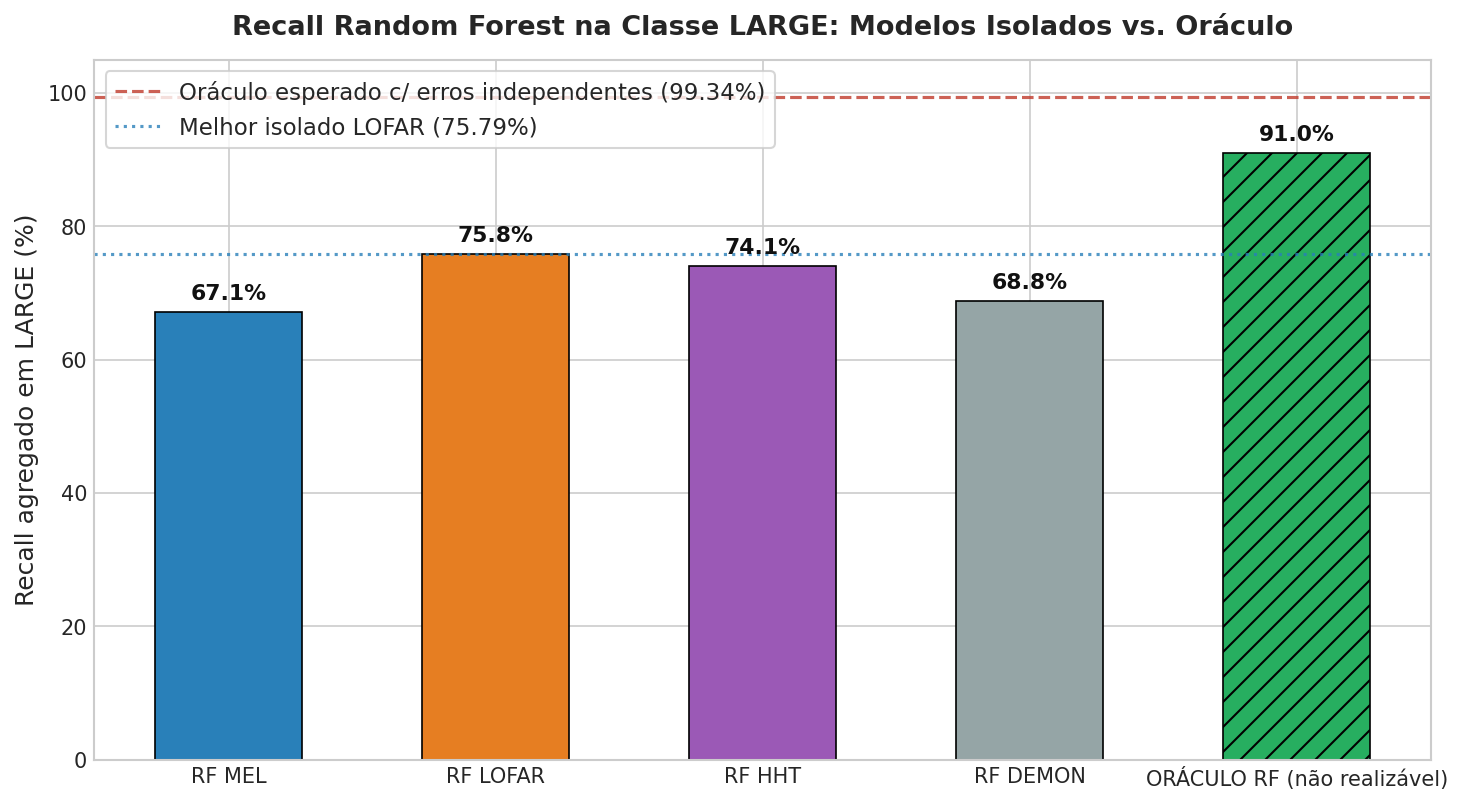

In [4]:
# 3. Gráfico: Desempenho isolado vs. oráculo (observado e esperado sob independência)
iso = A['isolado']
display(iso)
labels = [f'RF {r}' for r in iso.index] + ['ORÁCULO RF (não realizável)']
vals = list(iso['Recall agregado (%)']) + [A['oraculo']['agregado']]
plt.figure(figsize=(10, 5.5))
colors = ['#2980b9', '#e67e22', '#9b59b6', '#95a5a6', '#27ae60']
bars = plt.bar(labels, vals, color=colors, width=0.55, edgecolor='black', linewidth=0.8)
bars[-1].set_hatch('//')
plt.axhline(A['oraculo']['esp_indep'], color='#c0392b', linestyle='--', lw=1.5, alpha=0.8,
            label=f"Oráculo esperado c/ erros independentes ({A['oraculo']['esp_indep']:.2f}%)")
plt.axhline(iso.loc[A['melhor'], 'Recall agregado (%)'], color='#2980b9', linestyle=':', lw=1.5, alpha=0.8,
            label=f"Melhor isolado {A['melhor']} ({iso.loc[A['melhor'], 'Recall agregado (%)']:.2f}%)")
plt.title(f'Recall Random Forest na Classe {CLASSE}: Modelos Isolados vs. Oráculo', fontweight='bold', pad=12)
plt.ylabel(f'Recall agregado em {CLASSE} (%)')
plt.ylim(0, 105)
for bar in bars:
    h = bar.get_height()
    plt.annotate(f'{h:.1f}%', xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 4), textcoords='offset points',
                 ha='center', va='bottom', fontsize=10.5, fontweight='bold', color='#111')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

## 4. Grau de Consenso, Efeito Reverso e Votação em `LARGE` (RF)

### 4.1 Pirâmide de Consenso
- **Unanimidade (4/4 certas):** 991 instâncias (46,31%);
- **Alto consenso (3/4 certas):** 465 instâncias (21,73%);
- **Consenso dividido (2/4 certas):** 265 instâncias (12,38%);
- **Resgate exclusivo (1/4 certa):** 226 instâncias (10,56%);
- **Erro comum (0/4 certas):** 193 instâncias (9,02%).

### 4.2 Efeito reverso a partir do melhor isolado (LOFAR)
- **LOFAR → MEL:** mantém 1.316, perde 306 (18,87% dos acertos do LOFAR) e resgata 120 (23,17% dos erros) — saldo **-186** instâncias;
- **LOFAR → HHT:** mantém 1.448, perde 174 (10,73% dos acertos do LOFAR) e resgata 137 (26,45% dos erros) — saldo **-37** instâncias;
- **LOFAR → DEMON:** mantém 1.233, perde 389 (23,98% dos acertos do LOFAR) e resgata 239 (46,14% dos erros) — saldo **-150** instâncias;

Trocar de entrada sem um critério de seleção reduz os acertos quando o saldo é negativo.

### 4.3 Votação: "≥2/4" vs. voto real
- **≥3/4:** 68,04% (1.456 instâncias);
- **≥2/4:** 80,42% (1.721 instâncias). Esse número **não é um voto realizável**: conta como acerto os 158 empates 2×2 (duas entradas certas contra duas que concordam numa mesma classe errada);
- **Voto real** (pluralidade entre as 4 entradas, empate sorteado; `R.majority_vote`): recall em `LARGE` de **77,10% ± 2,59**, contra 75,79% ± 2,00 do LOFAR isolado. Pelo F-test 5×2cv o voto real **não difere significativamente** do melhor isolado nesta classe (p = 0,553);
- No SP global (4 classes), o voto real tem 62,76 ± 2,10, contra 63,07 ± 1,81 do RF LOFAR isolado: **equivalente** (p = 0,783);
- **Oráculo (≥1/4):** 90,98% (1.947 instâncias) — teto não realizável.

,Instâncias,% da classe,Gravações distintas
Nível,,,
4 de 4 acertam,991,46.31,314
3 de 4 acertam,465,21.73,215
2 de 4 acertam,265,12.38,144
1 de 4 acertam,226,10.56,122
0 de 4 acertam,193,9.02,73


,Mantém acertos,Perde acertos,Resgata erros,% dos acertos perdidos,% dos erros resgatados,Saldo (instâncias)
Troca,,,,,,
LOFAR → MEL,1316,306,120,18.87,23.17,-186
LOFAR → HHT,1448,174,137,10.73,26.45,-37
LOFAR → DEMON,1233,389,239,23.98,46.14,-150


,Recall LARGE (%),Observação
Critério,,
Unanimidade (4/4),46.31,contagem agregada
Maioria estrita (≥3/4),68.04,contagem agregada
≥2/4 (empate 2×2 contado como acerto),80.42,NÃO realizável: inclui 158 empates 2×2
"Voto real (pluralidade, empate sorteado)",77.10,média ± 2.59 nos folds; F-test vs LOFAR: p = 0...
Melhor isolado (LOFAR),75.79,média ± 2.00 nos folds
Oráculo (≥1/4),90.98,NÃO realizável; esperado c/ erros independente...


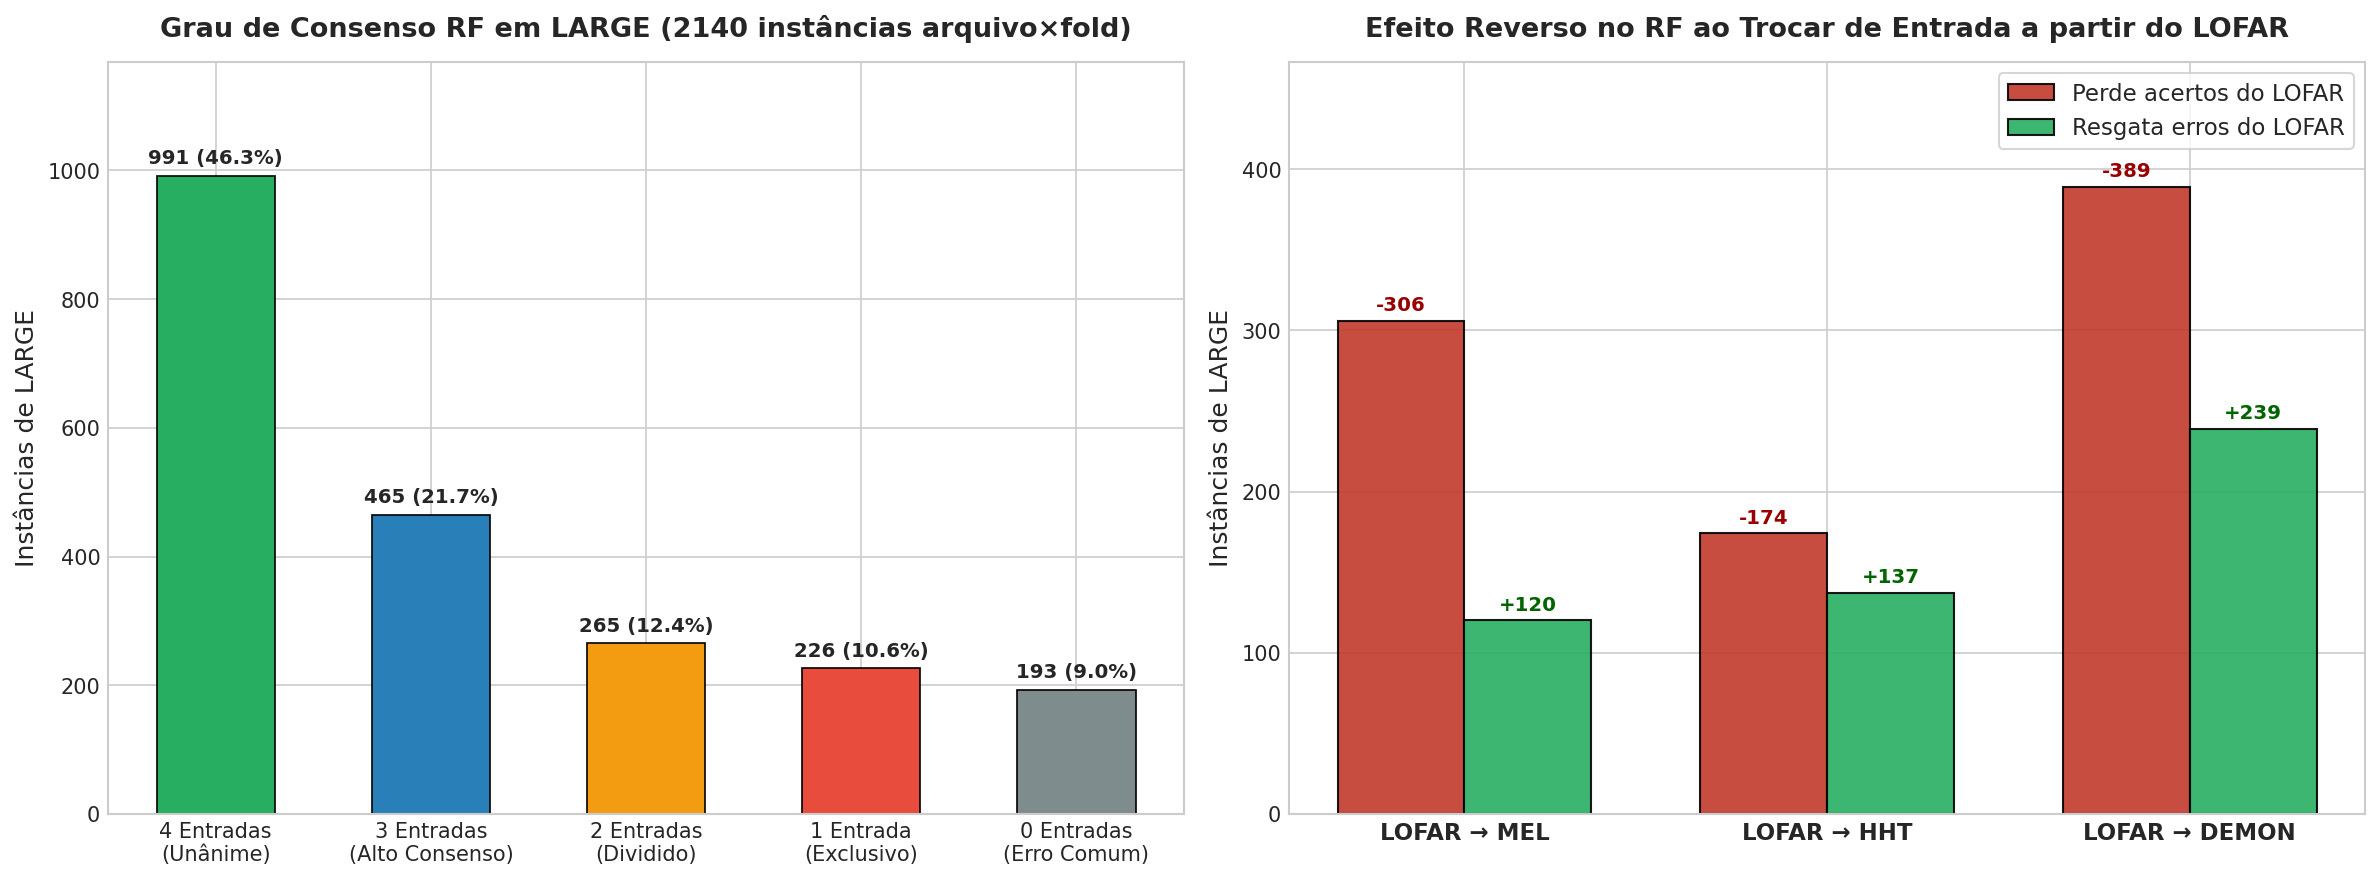

In [5]:
# 4. Visualização do Grau de Consenso e do Efeito Reverso em LARGE (RF)
display(A['consenso'])
display(A['reverso'])
display(tabela_voto(A))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
cons = A['consenso']
labels_cons = ['4 Entradas\n(Unânime)', '3 Entradas\n(Alto Consenso)', '2 Entradas\n(Dividido)',
               '1 Entrada\n(Exclusivo)', '0 Entradas\n(Erro Comum)']
bars1 = ax1.bar(labels_cons, cons['Instâncias'], color=['#27ae60', '#2980b9', '#f39c12', '#e74c3c', '#7f8c8d'],
                edgecolor='black', linewidth=0.8, width=0.55)
ax1.set_title(f"Grau de Consenso RF em {CLASSE} ({A['n_inst']} instâncias arquivo×fold)", fontweight='bold', pad=12)
ax1.set_ylabel(f'Instâncias de {CLASSE}')
ax1.set_ylim(0, cons['Instâncias'].max() * 1.18)
for bar, pct in zip(bars1, cons['% da classe']):
    h = bar.get_height()
    ax1.annotate(f'{int(h)} ({pct:.1f}%)', xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 4),
                 textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold')

rev = A['reverso']
x = np.arange(len(rev))
w = 0.35
r1 = ax2.bar(x - w / 2, rev['Perde acertos'], w, label=f"Perde acertos do {A['melhor']}", color='#c0392b', alpha=0.9, edgecolor='black')
r2 = ax2.bar(x + w / 2, rev['Resgata erros'], w, label=f"Resgata erros do {A['melhor']}", color='#27ae60', alpha=0.9, edgecolor='black')
ax2.set_title(f"Efeito Reverso no RF ao Trocar de Entrada a partir do {A['melhor']}", fontweight='bold', pad=12)
ax2.set_ylabel(f'Instâncias de {CLASSE}')
ax2.set_xticks(x)
ax2.set_xticklabels(rev.index, fontweight='bold', fontsize=11)
ax2.set_ylim(0, max(rev['Perde acertos'].max(), rev['Resgata erros'].max()) * 1.2)
ax2.legend(loc='upper right', frameon=True)
for rect in r1:
    ax2.annotate(f'-{int(rect.get_height())}', xy=(rect.get_x() + rect.get_width() / 2, rect.get_height()), xytext=(0, 3),
                 textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#900')
for rect in r2:
    ax2.annotate(f'+{int(rect.get_height())}', xy=(rect.get_x() + rect.get_width() / 2, rect.get_height()), xytext=(0, 3),
                 textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#006400')
plt.tight_layout()
plt.show()

## 5. Resgates Exclusivos no Random Forest em `LARGE`

Em **226 instâncias (10,56%)** apenas uma das 4 florestas acertou. Elas correspondem a **122 gravações distintas** e **103 navios distintos** (a mesma gravação aparece em vários folds e pode ser resgatada por entradas diferentes em cada um):

1. **DEMON:** 112 instâncias (5,23%), de 64 gravações e 57 navios; dessas gravações, **10** são resgate exclusivo do DEMON em **todas** as suas aparições de teste.
2. **HHT:** 47 instâncias (2,20%), de 29 gravações e 25 navios; dessas gravações, **3** são resgate exclusivo do HHT em **todas** as suas aparições de teste.
3. **LOFAR:** 45 instâncias (2,10%), de 23 gravações e 20 navios; dessas gravações, **4** são resgate exclusivo do LOFAR em **todas** as suas aparições de teste.
4. **MEL:** 22 instâncias (1,03%), de 14 gravações e 14 navios; dessas gravações, **2** são resgate exclusivo do MEL em **todas** as suas aparições de teste.

O maior número de resgates exclusivos é do **DEMON**. Os resgates são, em grande parte, **instáveis entre folds**: poucas gravações são resgatadas pela mesma entrada em todas as aparições. Um resgate exclusivo também não é aproveitável sem um critério que saiba, sem o rótulo, quando confiar naquela entrada.

,Instâncias,% da classe,Gravações distintas,Navios distintos,Gravações exclusivas em todas as aparições
Representação,,,,,
MEL,22,1.03,14,14,2
LOFAR,45,2.10,23,20,4
HHT,47,2.20,29,25,3
DEMON,112,5.23,64,57,10


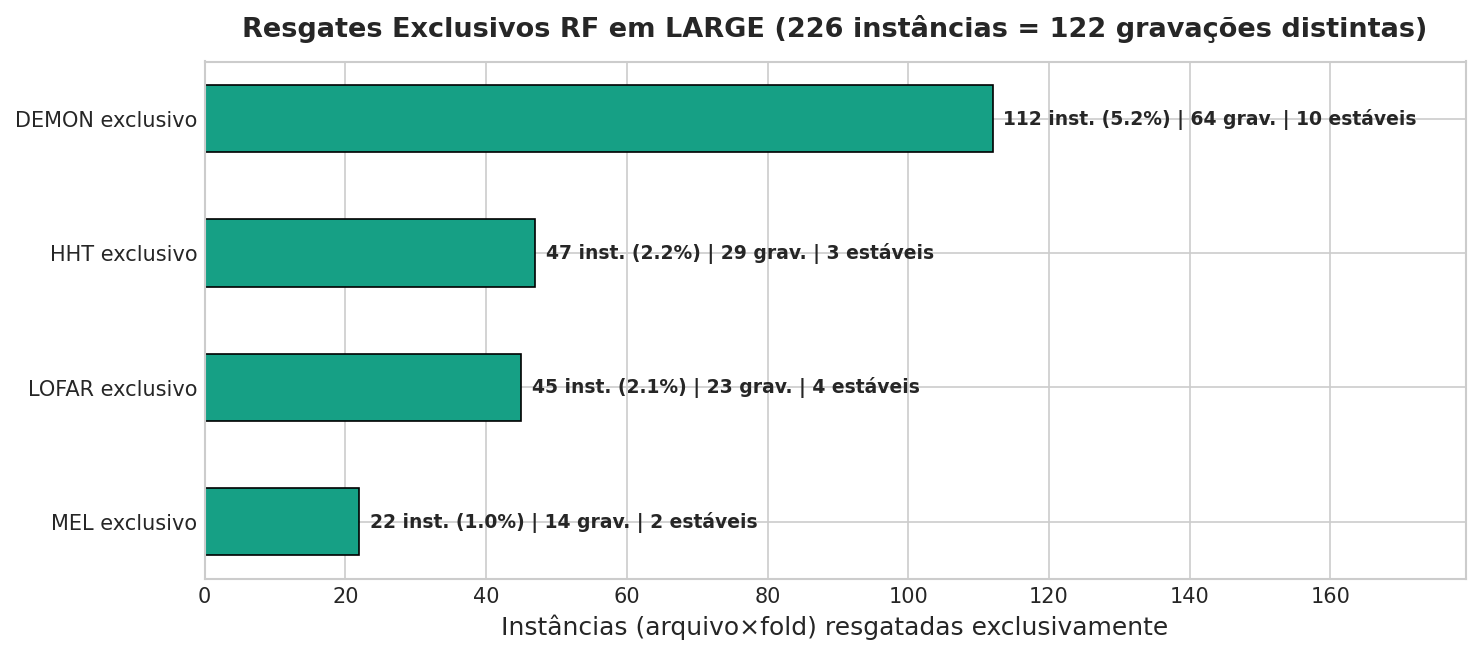

In [6]:
# 5. Gráfico: Resgates Exclusivos na Classe LARGE (RF)
ex = A['exclusivos'].sort_values('Instâncias')
display(A['exclusivos'])
plt.figure(figsize=(10, 4.5))
bars_excl = plt.barh([f'{r} exclusivo' for r in ex.index], ex['Instâncias'], color='#16a085', height=0.5,
                     edgecolor='black', linewidth=0.8)
plt.title(f"Resgates Exclusivos RF em {CLASSE} ({A['excl_total']['inst']} instâncias = {A['excl_total']['grav']} gravações distintas)",
          fontweight='bold', pad=12)
plt.xlabel('Instâncias (arquivo×fold) resgatadas exclusivamente')
plt.xlim(0, ex['Instâncias'].max() * 1.6)
for bar, (r, row) in zip(bars_excl, ex.iterrows()):
    w = bar.get_width()
    plt.annotate(f"{int(w)} inst. ({row['% da classe']:.1f}%) | {int(row['Gravações distintas'])} grav. | "
                 f"{int(row['Gravações exclusivas em todas as aparições'])} estáveis",
                 xy=(w, bar.get_y() + bar.get_height() / 2), xytext=(5, 0), textcoords='offset points',
                 ha='left', va='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Padrões de Erro em `LARGE`: Para Onde Cada Entrada Envia o Navio Grande no RF?

Distribuição dos erros de cada entrada (instâncias agregadas):

| Entrada | Erros | `SMALL` | `MEDIUM` | `BACKGROUND` | Principal destino |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **MEL** | 704 | 55,82% | 41,62% | 2,56% | `SMALL` |
| **LOFAR** | 518 | 51,93% | 44,02% | 4,05% | `SMALL` |
| **HHT** | 555 | 71,71% | 25,41% | 2,88% | `SMALL` |
| **DEMON** | 668 | 80,84% | 16,02% | 3,14% | `SMALL` |

> **Hipóteses físicas (não testadas nesta análise).** Conjecturas para orientar trabalho futuro; nada nas predições as confirma:
> - DEMON: a modulação pela rotação lenta de eixo de navios grandes (< 2 Hz) poderia separar parte dos `LARGE`; quando essa modulação não é captada, o envelope residual poderia se parecer com o de embarcações pequenas;
> - LOFAR: raias tonais de maquinário poderiam explicar a vantagem do LOFAR nesta classe.

,Erros (instâncias),→ SMALL (%),→ MEDIUM (%),→ BACKGROUND (%)
Representação,,,,
MEL,704,55.82,41.62,2.56
LOFAR,518,51.93,44.02,4.05
HHT,555,71.71,25.41,2.88
DEMON,668,80.84,16.02,3.14


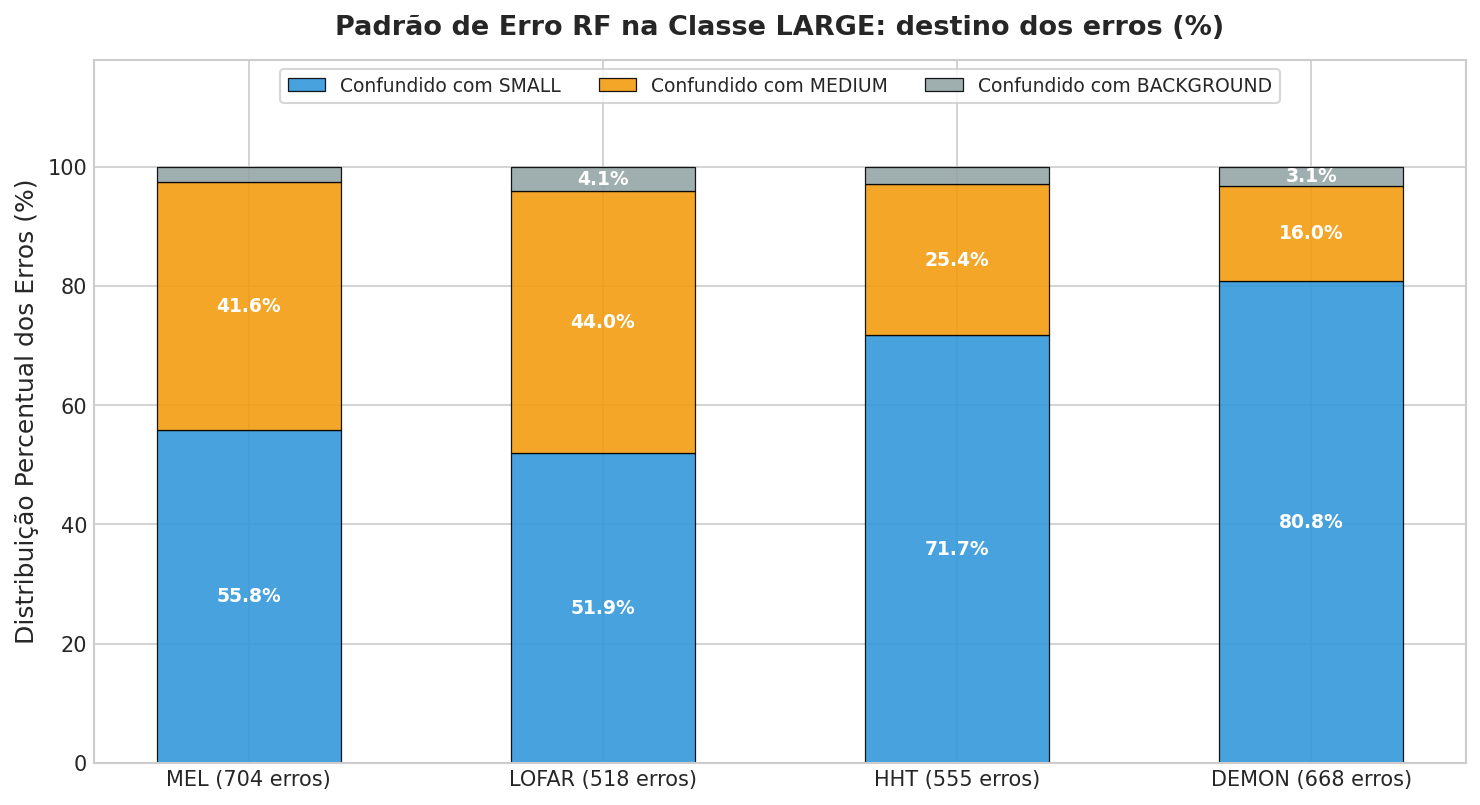

In [7]:
# 6. Gráfico: Destino do Erro em LARGE por Representação (RF)
er = A['erros']
display(er)
cols = [c for c in er.columns if c.startswith('→')]
cores = {'SMALL': '#3498db', 'MEDIUM': '#f39c12', 'LARGE': '#2ecc71', 'BACKGROUND': '#95a5a6'}
plt.figure(figsize=(10, 5.5))
bottom = np.zeros(len(er))
for c in cols:
    alvo = c.replace('→ ', '').replace(' (%)', '')
    vals = er[c].values.astype(float)
    plt.bar(er.index, vals, 0.52, bottom=bottom, label=f'Confundido com {alvo}', color=cores[alvo], alpha=0.9,
            edgecolor='black', linewidth=0.6)
    for i, (vv, bb) in enumerate(zip(vals, bottom)):
        if vv > 3:
            plt.text(i, bb + vv / 2, f'{vv:.1f}%', ha='center', va='center', fontsize=9, fontweight='bold', color='white')
    bottom += vals
plt.xticks(range(len(er)), [f"{r} ({n} erros)" for r, n in zip(er.index, er['Erros (instâncias)'])])
plt.title(f'Padrão de Erro RF na Classe {CLASSE}: destino dos erros (%)', fontweight='bold', pad=12)
plt.ylabel('Distribuição Percentual dos Erros (%)')
plt.ylim(0, 118)
plt.legend(loc='upper center', ncol=3, frameon=True, fontsize=9)
plt.tight_layout()
plt.show()

## 7. Painel Consolidado (figura do script de origem)

A figura abaixo foi gerada por `scratch/generate_rf_predictions_and_analysis.py`, que desempata o voto das janelas pela menor classe. Por isso suas contagens podem diferir das células acima em poucas instâncias; **os valores de referência são os das células deste notebook**. A figura também usa a contagem agregada de instâncias, não de gravações.

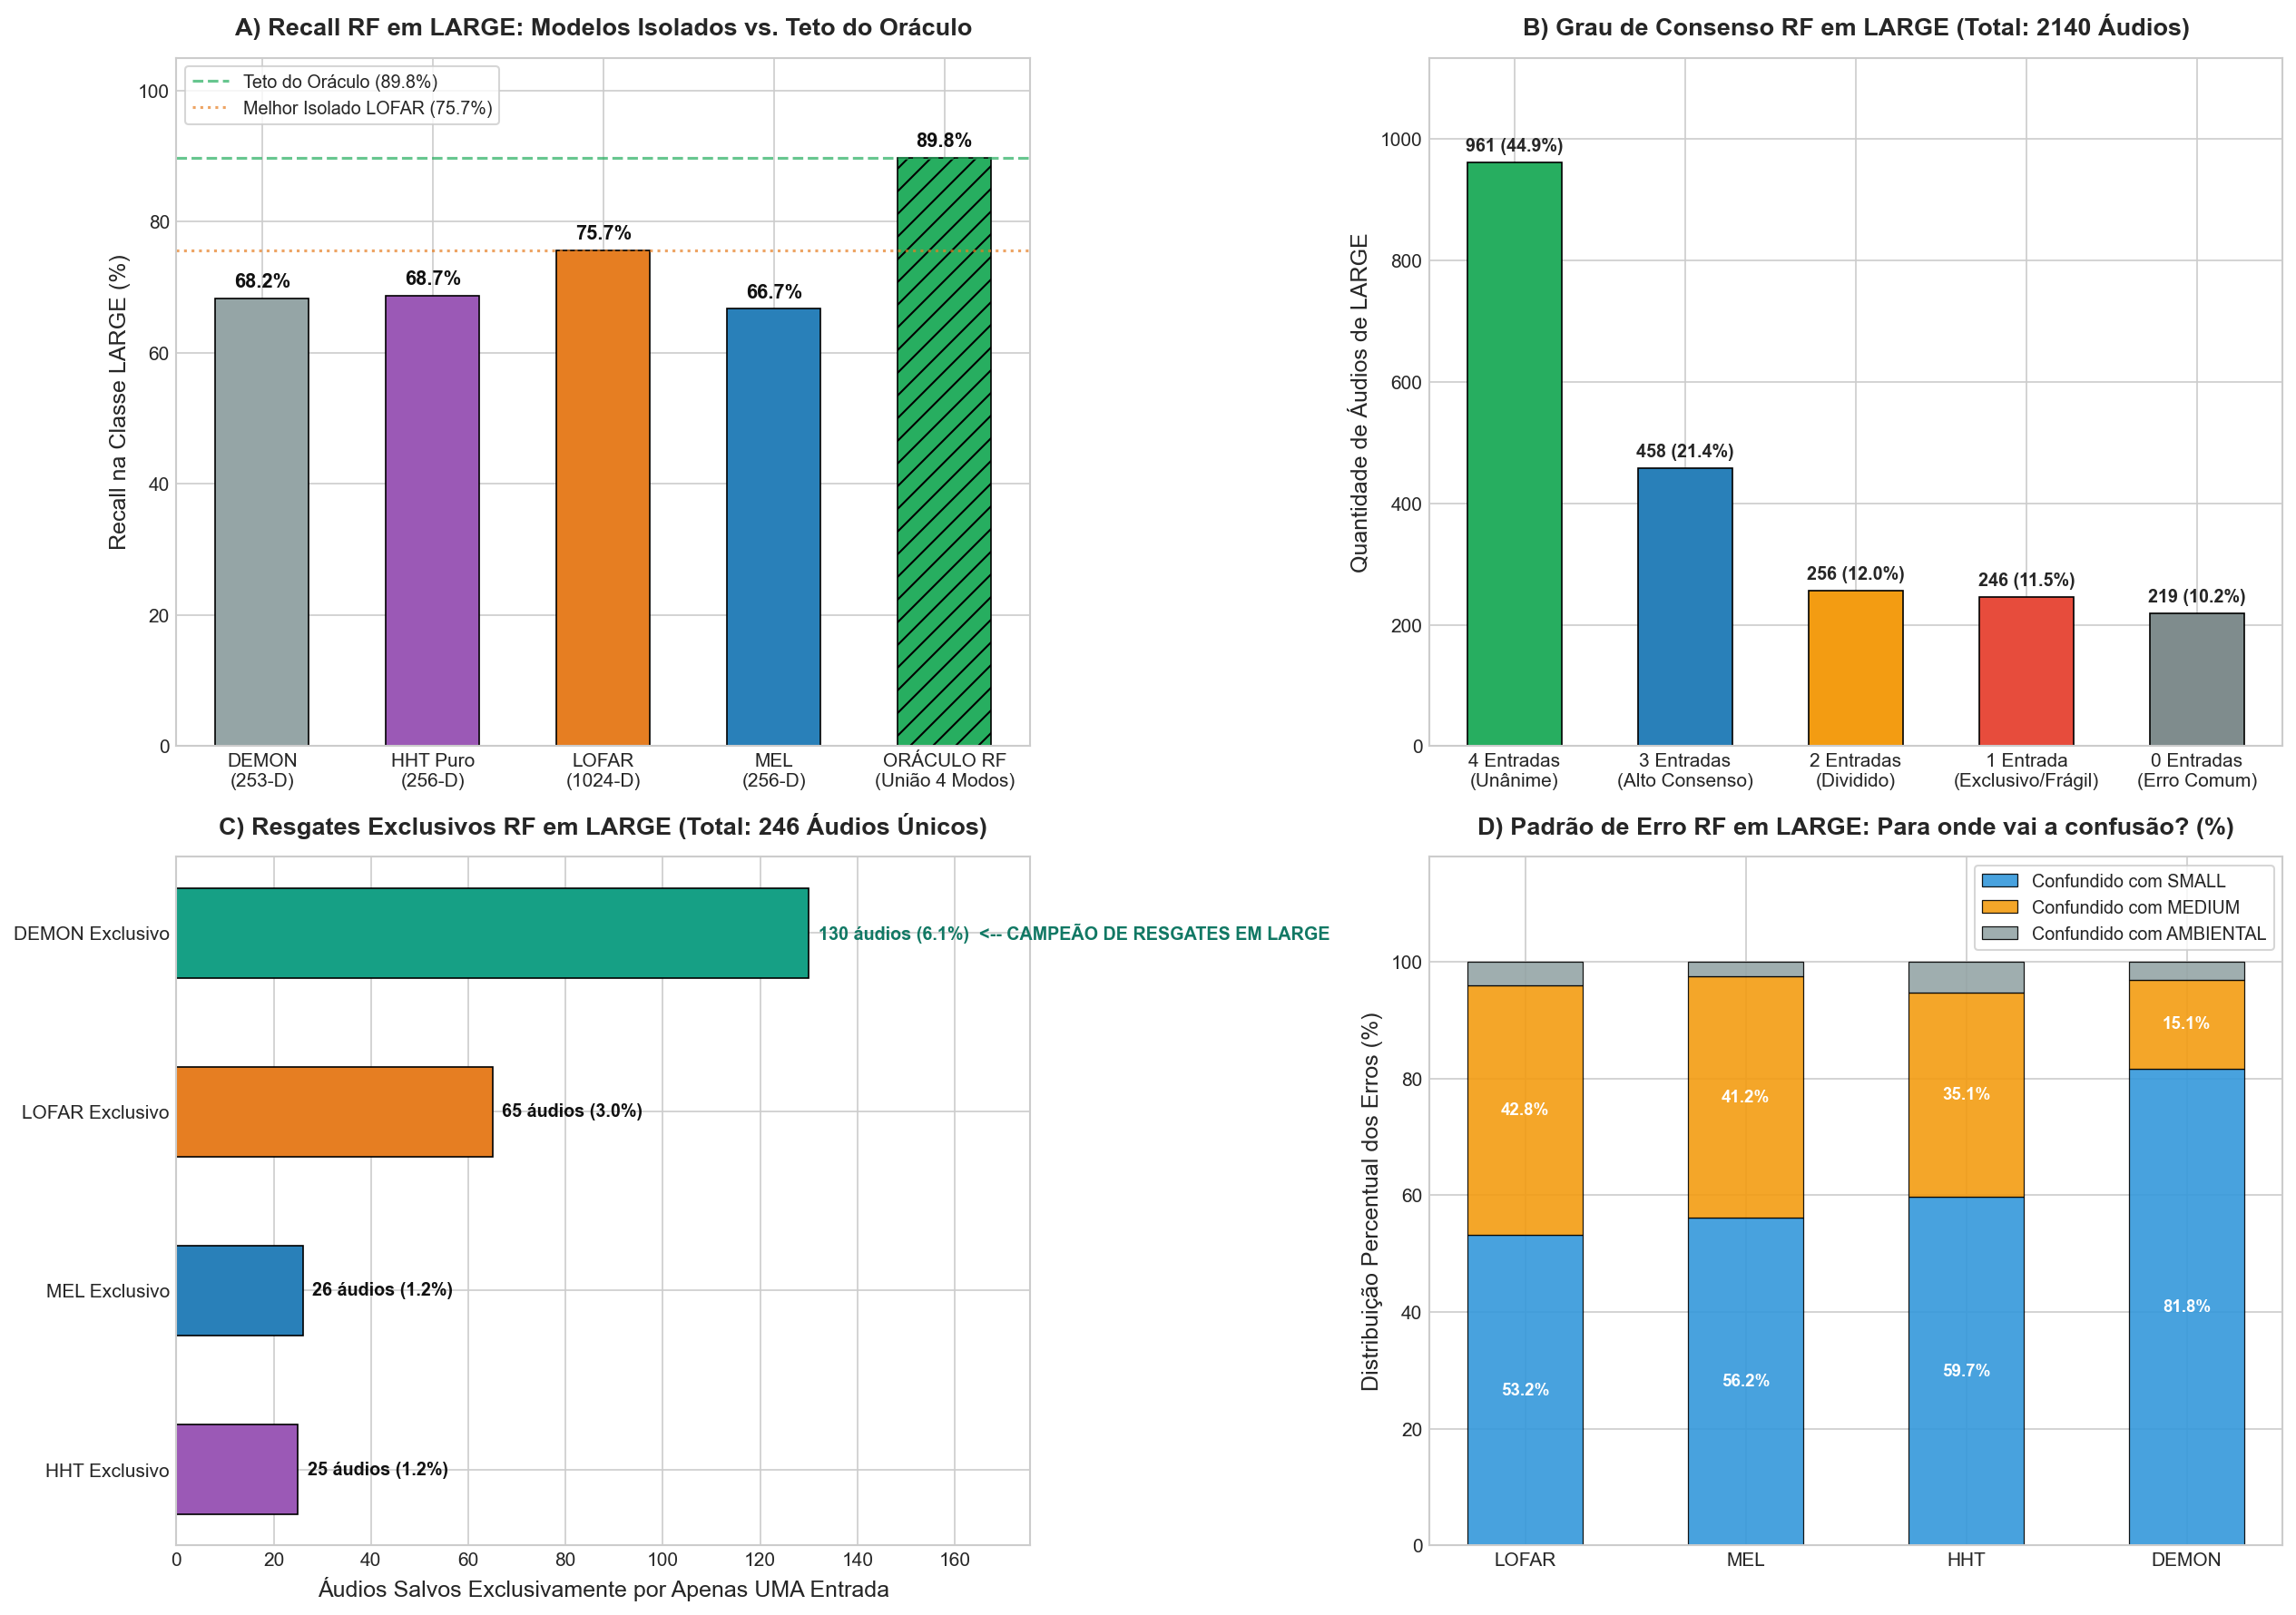

In [8]:
# 7. Exibição do painel salvo em disco (com fallback de caminho para cwd = notebooks/)
from IPython.display import Image
img_name = 'analise_complementaridade_rf_large_oraculo.png'
for img_path in (os.path.join('reports', img_name), os.path.join('..', 'reports', img_name)):
    if os.path.exists(img_path):
        display(Image(filename=img_path))
        break
else:
    print(f"Imagem {img_name} não encontrada em reports/ nem ../reports/. "
          "Execute 'scratch/generate_rf_predictions_and_analysis.py' para gerá-la.")

## 8. Comparativo Trilateral em `LARGE`: SVM Nyström vs. MLP vs. Random Forest

A tabela abaixo é calculada com a mesma função para as três famílias (SVM: Notebook 13; MLP: Notebook 16; RF: Notebook 19). Os experimentos de cada família estão em `FAMILIAS`. As famílias **não são homogêneas**: SVM HHT/DEMON usam m = 4000, os mesmos do Notebook 13 (e são instáveis entre folds); MLP HHT/DEMON vêm de um script ad hoc (30 épocas, sem validação); RF MEL/LOFAR usam as features de 5,12 s.

**Melhor isolado (recall médio em `LARGE` nos folds), com F-test 5×2cv:**
- RF LOFAR (75,79%) vs. SVM LOFAR (76,31%): o recall do RF não difere significativamente (p = 0,429).
- RF LOFAR (75,79%) vs. MLP LOFAR (74,72%): o recall do RF não difere significativamente (p = 0,524).

**Oráculos (não realizáveis):** SVM 90,84% (esperado sob independência 99,08%); MLP 89,25% (esperado sob independência 99,12%); RF 90,98% (esperado sob independência 99,34%). Em todas as famílias o oráculo observado fica abaixo do esperado sob independência, isto é, os erros são correlacionados. Com 4 entradas, um oráculo alto não indica um sistema realizável.

**Unanimidade 4/4:** SVM 40,14%; MLP 44,44%; RF 46,31%.

In [9]:
# 8. Comparativo trilateral calculado (SVM vs MLP vs RF) na classe LARGE
tab, A_fam = resumo_familias(CLASSE)
display(tab)
for f, (F, p) in f_test_melhores(A_fam, CLASSE).items():
    print(f"F-test 5x2cv do recall {CLASSE}: RF {A_fam['RF']['melhor']} vs {f} {A_fam[f]['melhor']} -> F = {F:.2f}, p = {p:.3f}")

,SVM,MLP,RF
Melhor isolado: recall médio ± desvio (%),LOFAR: 76.31 ± 4.38,LOFAR: 74.72 ± 4.30,LOFAR: 75.79 ± 2.00
"Oráculo observado (agregado, %)",90.84,89.25,90.98
Oráculo esperado c/ erros independentes (%),99.08,99.12,99.34
Unanimidade 4/4 (%),40.14,44.44,46.31
Erro comum 0/4 (%),9.16,10.75,9.02
Maior resgate exclusivo,DEMON: 122 inst. / 78 grav.,DEMON: 131 inst. / 72 grav.,DEMON: 112 inst. / 64 grav.
"≥2/4 com empates (não realizável, %)",79.35,78.50,80.42
Voto real: recall (%) [p vs melhor isolado],76.31 ± 6.19 [p = 0.749],75.84 ± 3.61 [p = 0.469],77.10 ± 2.59 [p = 0.553]


F-test 5x2cv do recall LARGE: RF LOFAR vs SVM LOFAR -> F = 1.24, p = 0.429
F-test 5x2cv do recall LARGE: RF LOFAR vs MLP LOFAR -> F = 1.02, p = 0.524


## 9. Síntese: SVM vs. MLP vs. Random Forest nas Três Classes de Navio

Consolidação dos Notebooks 13 a 21, calculada na célula abaixo com o mesmo código (instâncias arquivo × fold; as famílias não são homogêneas — ver Seção 8):

1. **Oráculos (não realizáveis):** o maior oráculo é do RF em `SMALL`, do MLP em `MEDIUM` e do RF em `LARGE`. Em todos os 9 casos o oráculo observado fica abaixo do esperado sob erros independentes: as entradas erram de forma correlacionada.
2. **Maior número de resgates exclusivos por família:** `SMALL`: SVM → HHT, MLP → DEMON, RF → DEMON; `MEDIUM`: SVM → MEL, MLP → MEL, RF → MEL; `LARGE`: SVM → DEMON, MLP → DEMON, RF → DEMON. Esses resgates são contados em instâncias e são, em grande parte, instáveis entre folds.
3. **Unanimidade 4/4 por classe (faixa entre famílias):** `SMALL` 4,44–17,13%; `MEDIUM` 25,44–30,54%; `LARGE` 40,14–46,31%. Em todas as famílias, a unanimidade cresce de `SMALL` para `MEDIUM` e para `LARGE`, sem sobreposição das faixas. Isso descreve o consenso dos modelos; não identifica a causa física (marulho, distância, etc.).
4. **Votação real:** Em nenhuma combinação classe × família o voto real difere significativamente do melhor isolado (F-test 5×2cv, p ≥ 0,05). Um oráculo alto não se converte em ganho com voto simples.

In [10]:
# 9. Síntese: SVM vs MLP vs RF nas três classes de navio
linhas = []
for cl in ('SMALL', 'MEDIUM', 'LARGE'):
    for f in ('SVM', 'MLP', 'RF'):
        a = analise_classe(f, cl)
        ex = a['exclusivos']
        linhas.append({'Classe': cl, 'Família': f,
                       'Melhor isolado': a['melhor'], 'Recall melhor isolado (%)': a['voto']['melhor'][0],
                       'Unanimidade 4/4 (%)': a['consenso']['% da classe'].iloc[0],
                       'Erro comum 0/4 (%)': a['consenso']['% da classe'].iloc[-1],
                       'Oráculo obs. (%)': a['oraculo']['agregado'],
                       'Oráculo esperado indep. (%)': a['oraculo']['esp_indep'],
                       'Maior resgate exclusivo': ex['Instâncias'].idxmax(),
                       'Voto real (%)': a['voto']['recall'][0], 'p voto vs melhor': a['voto']['p']})
sintese = pd.DataFrame(linhas).set_index(['Classe', 'Família'])
display(sintese)

Melhor isolado  Recall melhor isolado (%)  Unanimidade 4/4 (%)  \
Classe Família                                                                  
SMALL  SVM                MEL                      50.73                 4.83   
       MLP              LOFAR                      46.35                 4.44   
       RF                 MEL                      57.87                17.13   
MEDIUM SVM                MEL                      60.40                26.98   
       MLP                MEL                      64.09                30.54   
       RF                 MEL                      58.72                25.44   
LARGE  SVM              LOFAR                      76.31                40.14   
       MLP              LOFAR                      74.72                44.44   
       RF               LOFAR                      75.79                46.31   

                Erro comum 0/4 (%)  Oráculo obs. (%)  \
Classe Família                                         
SMALL  SVM                   18.82             81.18   
       MLP                   23.82             76.18   
       RF                    14.04             85.96   
MEDIUM SVM                   17.79             82.21   
       MLP                   17.32             82.68   
       RF                    24.36             75.64   
LARGE  SVM                    9.16             90.84   
       MLP                   10.75             89.25   
       RF                     9.02             90.98   

                Oráculo esperado indep. (%) Maior resgate exclusivo  \
Classe Família                                                        
SMALL  SVM                            88.51                     HHT   
       MLP                            85.49                   DEMON   
       RF                             95.12                   DEMON   
MEDIUM SVM                            95.52                     MEL   
       MLP                            96.75                     MEL   
       RF                             93.43                     MEL   
LARGE  SVM                            99.08                   DEMON   
       MLP                            99.12                   DEMON   
       RF                             99.34                   DEMON   

                Voto real (%)  p voto vs melhor  
Classe Família                                   
SMALL  SVM              46.40              0.41  
       MLP              42.30              0.32  
       RF               57.70              0.81  
MEDIUM SVM              59.26              0.71  
       MLP              61.88              0.68  
       RF               50.40              0.18  
LARGE  SVM              76.31              0.75  
       MLP              75.84              0.47  
       RF               77.10              0.55